In [ ]:
!git clone https://github.com/Li-Chongyi/Zero-DCE.git

%cd /content/Zero-DCE/Zero-DCE_code



Cloning into 'Zero-DCE'...
remote: Enumerating objects: 236, done.
remote: Counting objects: 100% (39/39), done.
remote: Compressing objects: 100% (11/11), done.
remote: Total 236 (delta 30), reused 28 (delta 28), pack-reused 197 (from 1)
Receiving objects: 100% (236/236), 30.89 MiB | 21.25 MiB/s, done.
Resolving deltas: 100% (43/43), done.
/content/Zero-DCE/Zero-DCE_code


In [ ]:
!pip install -q torch torchvision pillow opencv-python numpy

In [ ]:
from google.colab import drive
from pathlib import Path
import os
import subprocess
import sys

drive.mount("/content/drive")

REPO = Path("/content/Zero-DCE/Zero-DCE_code")

if not (REPO / "model.py").exists():
    subprocess.run(
        ["git", "clone", "https://github.com/Li-Chongyi/Zero-DCE.git",
         "/content/Zero-DCE"],
        check=True
    )

os.chdir(REPO)
print("Working directory:", Path.cwd())
print("GPU available:", __import__("torch").cuda.is_available())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Working directory: /content/Zero-DCE/Zero-DCE_code
GPU available: True


In [ ]:
%cd /content/Zero-DCE/Zero-DCE_code/

/content/Zero-DCE/Zero-DCE_code


In [ ]:
from pathlib import Path
from PIL import Image
import shutil
import time

sources = {
    "part1": Path("/content/drive/MyDrive/SICE_Part1/Part1"),
    "part2": Path("/content/drive/MyDrive/SICE_Part2/Part2"),
}

local = Path("/content/SICE_Training")
extensions = {".jpg", ".jpeg", ".png"}

for name, src in sources.items():
    assert src.exists(), f"Missing Drive folder: {src}"

    dst = local / name
    source_files = [
        p for p in src.rglob("*")
        if p.is_file() and p.suffix.lower() in extensions
    ]

    print(f"{name}: {len(source_files)} source images", flush=True)

    if dst.exists():
        local_files = [
            p for p in dst.rglob("*")
            if p.is_file() and p.suffix.lower() in extensions
        ]
    else:
        local_files = []

    if len(local_files) != len(source_files):
        print(f"Copying {name} to local storage...", flush=True)
        start = time.time()
        shutil.copytree(src, dst, dirs_exist_ok=True)
        print(f"Finished in {(time.time()-start)/60:.1f} min", flush=True)
    else:
        print(f"{name} already copied", flush=True)

train_paths = "/content/SICE_Training/part1,/content/SICE_Training/part2"

total = sum(
    1 for p in local.rglob("*")
    if p.is_file() and p.suffix.lower() in extensions
)

print("Total local images:", total)
assert total > 0, "No images were copied."

part1: 3381 source images
Copying part1 to local storage...
Finished in 5.6 min
part2: 2009 source images
Copying part2 to local storage...
Finished in 8.6 min
Total local images: 5390


In [ ]:
from pathlib import Path

loader_file = REPO / "dataloader.py"
code = loader_file.read_text()

start = code.index("def populate_train_list")
end = code.index("class lowlight_loader")

replacement = '''
def populate_train_list(lowlight_images_path):
    from pathlib import Path

    image_list = []
    for folder in lowlight_images_path.split(","):
        root = Path(folder.strip())
        if not root.is_dir():
            raise FileNotFoundError(root)

        image_list.extend(
            str(p) for p in root.rglob("*")
            if p.is_file() and p.suffix.lower()
            in {".jpg", ".jpeg", ".png"}
        )

    image_list.sort()
    random.shuffle(image_list)
    return image_list


'''

code = code[:start] + replacement + code[end:]
code = code.replace("Image.ANTIALIAS", "Image.Resampling.LANCZOS")
code = code.replace(
    "data_lowlight = Image.open(data_lowlight_path)",
    'data_lowlight = Image.open(data_lowlight_path).convert("RGB")'
)

loader_file.write_text(code)
print("Dataloader updated!")

import importlib
import dataloader
importlib.reload(dataloader)

dataset = dataloader.lowlight_loader(train_paths)
print("Ready to train:", len(dataset), "images")
print("Sample shape:", dataset[0].shape)

Dataloader updated!
Total training examples: 5390
Ready to train: 5390 images
Sample shape: torch.Size([3, 256, 256])


In [ ]:

from pathlib import Path

script = r'''
import argparse
import os
import random
from pathlib import Path

import numpy as np
import torch
import model
import dataloader
import Myloss


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


def weights_init(m):
    name = m.__class__.__name__
    if "Conv" in name:
        m.weight.data.normal_(0.0, 0.02)
    elif "BatchNorm" in name:
        m.weight.data.normal_(1.0, 0.02)
        m.bias.data.fill_(0)


def save_checkpoint(path, epoch, net, optimizer, seed):
    state = {
        "epoch": epoch,
        "seed": seed,
        "model": net.state_dict(),
        "optimizer": optimizer.state_dict(),
        "python_rng": random.getstate(),
        "numpy_rng": np.random.get_state(),
        "torch_rng": torch.get_rng_state(),
        "cuda_rng": (
            torch.cuda.get_rng_state_all()
            if torch.cuda.is_available() else None
        ),
    }

    temp_path = str(path) + ".tmp"
    torch.save(state, temp_path)
    os.replace(temp_path, path)
    print(f"Checkpoint saved at epoch {epoch}", flush=True)


def train(args):
    device = torch.device(
        "cuda" if torch.cuda.is_available() else "cpu"
    )

    print(f"Device: {device}", flush=True)
    print(f"Seed: {args.seed}", flush=True)

    set_seed(args.seed)

    save_dir = Path(args.save_dir)
    save_dir.mkdir(parents=True, exist_ok=True)

    checkpoint_path = save_dir / "latest.pth"
    final_path = save_dir / "final.pth"

    net = model.enhance_net_nopool().to(device)
    net.apply(weights_init)

    optimizer = torch.optim.Adam(
        net.parameters(),
        lr=0.0001,
        weight_decay=0.0001
    )

    L_color = Myloss.L_color()
    L_spa = Myloss.L_spa()
    L_exp = Myloss.L_exp(16, 0.6)
    L_TV = Myloss.L_TV()

    train_dataset = dataloader.lowlight_loader(args.train_path)

    if len(train_dataset) == 0:
        raise RuntimeError("No training images found!")

    train_loader = torch.utils.data.DataLoader(
        train_dataset,
        batch_size=args.batch_size,
        shuffle=True,
        num_workers=32,
        pin_memory=(device.type == "cuda")
    )

    start_epoch = 0

    if checkpoint_path.exists():
        checkpoint = torch.load(
            checkpoint_path,
            map_location=device,
            weights_only=False
        )

        if checkpoint["seed"] != args.seed:
            raise RuntimeError("Checkpoint seed mismatch")

        net.load_state_dict(checkpoint["model"])
        optimizer.load_state_dict(checkpoint["optimizer"])

        random.setstate(checkpoint["python_rng"])
        np.random.set_state(checkpoint["numpy_rng"])
        torch.set_rng_state(checkpoint["torch_rng"])

        if device.type == "cuda" and checkpoint["cuda_rng"] is not None:
            torch.cuda.set_rng_state_all(checkpoint["cuda_rng"])

        start_epoch = checkpoint["epoch"]
        print(f"Resuming from epoch {start_epoch + 1}", flush=True)
    else:
        print("Starting from epoch 1", flush=True)

    if start_epoch >= args.epochs:
        if not final_path.exists():
            torch.save(net.state_dict(), final_path)
        print("Already completed!", flush=True)
        return

    net.train()

    for epoch in range(start_epoch, args.epochs):
        total_loss = 0.0

        for batch_idx, images in enumerate(train_loader):
            images = images.to(device)

            _, enhanced, A = net(images)

            loss_tv = 200 * L_TV(A)
            loss_spa = torch.mean(L_spa(enhanced, images))
            loss_col = 5 * torch.mean(L_color(enhanced))
            loss_exp = 10 * torch.mean(L_exp(enhanced))

            loss = loss_tv + loss_spa + loss_col + loss_exp

            optimizer.zero_grad()
            loss.backward()
            torch.nn.utils.clip_grad_norm_(net.parameters(), 0.1)
            optimizer.step()

            total_loss += loss.item()

            if (batch_idx + 1) % 50 == 0:
                print(
                    f"Seed {args.seed} | Epoch {epoch + 1}/{args.epochs} "
                    f"| Batch {batch_idx + 1}/{len(train_loader)}",
                    flush=True
                )

        completed = epoch + 1
        avg_loss = total_loss / len(train_loader)

        print(
            f"Seed {args.seed} | Epoch {completed}/{args.epochs} "
            f"| Loss {avg_loss:.6f}",
            flush=True
        )

        if completed % args.save_every == 0 or completed == args.epochs:
            save_checkpoint(
                checkpoint_path, completed,
                net, optimizer, args.seed
            )

    torch.save(net.state_dict(), final_path)
    print(f"Finished seed {args.seed}: {final_path}", flush=True)


if __name__ == "__main__":
    parser = argparse.ArgumentParser()
    parser.add_argument("--train_path", required=True)
    parser.add_argument("--save_dir", required=True)
    parser.add_argument("--seed", type=int, default=1)
    parser.add_argument("--epochs", type=int, default=100)
    parser.add_argument("--save_every", type=int, default=5)
    parser.add_argument("--batch_size", type=int, default=8)

    train(parser.parse_args())
'''

(REPO / "train_resumable.py").write_text(script)

print("Created train_resumable.py")

Created train_resumable.py


In [ ]:
import time
from torch.utils.data import DataLoader
import dataloader

paths = "/content/SICE_Training/part1,/content/SICE_Training/part2"

dataset = dataloader.lowlight_loader(paths)
loader = DataLoader(dataset, batch_size=8, num_workers=32)

start = time.time()
count = 0

for batch in loader:
    count += 1
    if count >= 20:
        break

elapsed = time.time() - start

print(f"20 batches: {elapsed:.2f} seconds")
print(f"Average loading time: {elapsed/count:.3f} seconds/batch")

Total training examples: 5390
20 batches: 3.73 seconds
Average loading time: 0.186 seconds/batch


In [ ]:
import shutil
from pathlib import Path

backup = Path("/content/drive/MyDrive/ZeroDCE_Results/code")
backup.mkdir(parents=True, exist_ok=True)

for filename in ["dataloader.py", "train_resumable.py"]:
    shutil.copy2(REPO / filename, backup / filename)

print("Training scripts backed up to Google Drive!")

Training scripts backed up to Google Drive!


In [ ]:
!python -u train_resumable.py \
    --train_path "/content/SICE_Training/part1,/content/SICE_Training/part2" \
    --save_dir "/content/drive/MyDrive/ZeroDCE_Results/checkpoints/seed_3" \
    --seed 3 \
    --epochs 100 \
    --save_every 5 \
    --batch_size 8

Device: cuda
Seed: 3
Total training examples: 5390
Starting from epoch 1
Seed 3 | Epoch 1/100 | Batch 50/674
Seed 3 | Epoch 1/100 | Batch 100/674
Seed 3 | Epoch 1/100 | Batch 150/674
Seed 3 | Epoch 1/100 | Batch 200/674
Seed 3 | Epoch 1/100 | Batch 250/674
Seed 3 | Epoch 1/100 | Batch 300/674
Seed 3 | Epoch 1/100 | Batch 350/674
Seed 3 | Epoch 1/100 | Batch 400/674
Seed 3 | Epoch 1/100 | Batch 450/674
Seed 3 | Epoch 1/100 | Batch 500/674
Seed 3 | Epoch 1/100 | Batch 550/674
Seed 3 | Epoch 1/100 | Batch 600/674
Seed 3 | Epoch 1/100 | Batch 650/674
Seed 3 | Epoch 1/100 | Loss 0.914670
Seed 3 | Epoch 2/100 | Batch 50/674
Seed 3 | Epoch 2/100 | Batch 100/674
Seed 3 | Epoch 2/100 | Batch 150/674
Seed 3 | Epoch 2/100 | Batch 200/674
Seed 3 | Epoch 2/100 | Batch 250/674
Seed 3 | Epoch 2/100 | Batch 300/674
Seed 3 | Epoch 2/100 | Batch 350/674
Seed 3 | Epoch 2/100 | Batch 400/674
Seed 3 | Epoch 2/100 | Batch 450/674
Seed 3 | Epoch 2/100 | Batch 500/674
Seed 3 | Epoch 2/100 | Batch 550/674
Seed

Evaluation

In [ ]:
from google.colab import drive
from pathlib import Path
import os
import subprocess
import sys
import torch

drive.mount("/content/drive")

REPO = Path("/content/Zero-DCE/Zero-DCE_code")

if not (REPO / "model.py").exists():
    subprocess.run(
        [
            "git", "clone",
            "https://github.com/Li-Chongyi/Zero-DCE.git",
            "/content/Zero-DCE"
        ],
        check=True
    )

os.chdir(REPO)

!pip -q install scikit-image pandas matplotlib pillow requests tqdm

print("Working directory:", os.getcwd())
print("GPU available:", torch.cuda.is_available())

CHECKPOINTS = Path(
    "/content/drive/MyDrive/ZeroDCE_Results/checkpoints"
)

for seed in [1, 2, 3]:
    checkpoint = CHECKPOINTS / f"seed_{seed}/final.pth"
    assert checkpoint.exists(), f"Missing: {checkpoint}"
    print(f"Seed {seed}: checkpoint found")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Working directory: /content/Zero-DCE/Zero-DCE_code
GPU available: True
Seed 1: checkpoint found
Seed 2: checkpoint found
Seed 3: checkpoint found


In [ ]:
from pathlib import Path
import requests
import zipfile

DATA_ROOT = Path("/content/LOL_Dataset")
DATA_ROOT.mkdir(parents=True, exist_ok=True)

ZIP_PATH = Path("/content/lol_dataset.zip")

URL = (
    "https://huggingface.co/datasets/geekyrakshit/"
    "LoL-Dataset/resolve/main/lol_dataset.zip"
)

if not ZIP_PATH.exists():
    print("Downloading LOL dataset...", flush=True)

    with requests.get(URL, stream=True, timeout=120) as response:
        response.raise_for_status()

        with open(ZIP_PATH, "wb") as f:
            for chunk in response.iter_content(chunk_size=1024 * 1024):
                if chunk:
                    f.write(chunk)

    print("Download completed!")

if not any(DATA_ROOT.iterdir()):
    print("Extracting dataset...", flush=True)

    with zipfile.ZipFile(ZIP_PATH, "r") as z:
        z.extractall(DATA_ROOT)

print("Dataset extracted!")

Download completed!
Extracting dataset...
Dataset extracted!


In [ ]:
from pathlib import Path

eval_folders = [
    p for p in DATA_ROOT.rglob("*")
    if p.is_dir() and p.name.lower() == "eval15"
]

assert eval_folders, "Could not find the eval15 folder."

EVAL_ROOT = next(
    (
        p for p in eval_folders
        if (p / "low").is_dir() and (p / "high").is_dir()
    ),
    None
)

assert EVAL_ROOT is not None, (
    "Could not find eval15/low and eval15/high."
)

LOW_DIR = EVAL_ROOT / "low"
GT_DIR = EVAL_ROOT / "high"

extensions = {".png", ".jpg", ".jpeg", ".bmp"}

low_files = sorted(
    p for p in LOW_DIR.iterdir()
    if p.is_file() and p.suffix.lower() in extensions
)

gt_files = sorted(
    p for p in GT_DIR.iterdir()
    if p.is_file() and p.suffix.lower() in extensions
)

print("Testing dataset:", EVAL_ROOT)
print("Low-light images:", len(low_files))
print("Ground-truth images:", len(gt_files))

assert len(low_files) == 15
assert len(gt_files) == 15

Testing dataset: /content/LOL_Dataset/lol_dataset/eval15
Low-light images: 15
Ground-truth images: 15


In [ ]:

import torch
import numpy as np
import pandas as pd
from pathlib import Path
from PIL import Image
from tqdm.auto import tqdm
from skimage.metrics import (
    peak_signal_noise_ratio,
    structural_similarity
)

import model

SEEDS = [1, 2, 3]

CHECKPOINTS = Path(
    "/content/drive/MyDrive/ZeroDCE_Results/checkpoints"
)

OUTPUT = Path(
    "/content/drive/MyDrive/ZeroDCE_Results/evaluation_LOL"
)

OUTPUT.mkdir(parents=True, exist_ok=True)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Evaluating on:", device)

# Match test images by filename stem
low_dict = {p.stem: p for p in low_files}
gt_dict = {p.stem: p for p in gt_files}

assert len(low_dict) == len(low_files)
assert len(gt_dict) == len(gt_files)
assert set(low_dict) == set(gt_dict), (
    "Low-light and ground-truth filenames do not match."
)

names = sorted(low_dict.keys())
assert len(names) == 15

print("Matched testing pairs:", len(names))

all_metrics = []
seed_results = []

for seed in SEEDS:
    print(f"\n========== EVALUATING SEED {seed} ==========")

    checkpoint_path = (
        CHECKPOINTS / f"seed_{seed}" / "final.pth"
    )

    assert checkpoint_path.exists(), (
        f"Checkpoint missing: {checkpoint_path}"
    )

    net = model.enhance_net_nopool().to(device)

    state = torch.load(
        checkpoint_path,
        map_location=device,
        weights_only=True
    )

    net.load_state_dict(state)
    net.eval()

    seed_output = OUTPUT / f"seed_{seed}"
    enhanced_dir = seed_output / "enhanced"
    enhanced_dir.mkdir(parents=True, exist_ok=True)

    image_results = []

    with torch.inference_mode():
        for name in tqdm(names, desc=f"Seed {seed}"):
            low_path = low_dict[name]
            gt_path = gt_dict[name]

            low = np.asarray(
                Image.open(low_path).convert("RGB"),
                dtype=np.float32
            ) / 255.0

            gt = np.asarray(
                Image.open(gt_path).convert("RGB"),
                dtype=np.float32
            ) / 255.0

            if low.shape != gt.shape:
                raise ValueError(
                    f"Image pair has different dimensions: {name}"
                )

            # Convert input image to PyTorch tensor
            tensor = (
                torch.from_numpy(low)
                .permute(2, 0, 1)
                .unsqueeze(0)
                .to(device)
            )

            # Zero-DCE inference
            _, enhanced, _ = net(tensor)

            enhanced = (
                enhanced.squeeze(0)
                .clamp(0.0, 1.0)
                .permute(1, 2, 0)
                .cpu()
                .numpy()
            )

            # Convert output to 8-bit RGB
            enhanced_uint8 = (
                np.clip(enhanced * 255.0, 0, 255)
                .round()
                .astype(np.uint8)
            )

            # Save enhanced image
            save_path = enhanced_dir / f"{name}.png"

            Image.fromarray(enhanced_uint8).save(save_path)

            # Evaluate the saved 8-bit output
            pred = enhanced_uint8.astype(np.float32) / 255.0

            psnr = peak_signal_noise_ratio(
                gt, pred, data_range=1.0
            )

            ssim = structural_similarity(
                gt,
                pred,
                channel_axis=2,
                data_range=1.0
            )

            mae = np.mean(np.abs(gt - pred))

            result = {
                "Seed": seed,
                "Image": name,
                "PSNR": float(psnr),
                "SSIM": float(ssim),
                "MAE": float(mae)
            }

            image_results.append(result)
            all_metrics.append(result)

    # Calculate average over the testing images
    seed_df = pd.DataFrame(image_results)

    seed_df.to_csv(
        seed_output / "per_image_metrics.csv",
        index=False
    )

    seed_summary = {
        "Seed": seed,
        "PSNR": seed_df["PSNR"].mean(),
        "SSIM": seed_df["SSIM"].mean(),
        "MAE": seed_df["MAE"].mean()
    }

    seed_results.append(seed_summary)

    print(
        f"Seed {seed}: "
        f"PSNR={seed_summary['PSNR']:.4f}, "
        f"SSIM={seed_summary['SSIM']:.4f}, "
        f"MAE={seed_summary['MAE']:.4f}"
    )

    del net
    if device.type == "cuda":
        torch.cuda.empty_cache()

# Save combined results
per_image_df = pd.DataFrame(all_metrics)
seed_df = pd.DataFrame(seed_results)

per_image_df.to_csv(
    OUTPUT / "all_per_image_metrics.csv",
    index=False
)

seed_df.to_csv(
    OUTPUT / "seed_metrics.csv",
    index=False
)

print("\nAll evaluations completed!")
print(seed_df.to_string(index=False))
print("\nSaved results to:", OUTPUT)


Evaluating on: cuda
Matched testing pairs: 15

========== EVALUATING SEED 1 ==========


Seed 1:   0%|          | 0/15 [00:00<?, ?it/s]

Seed 1: PSNR=16.4981, SSIM=0.5610, MAE=0.1456

========== EVALUATING SEED 2 ==========


Seed 2:   0%|          | 0/15 [00:00<?, ?it/s]

Seed 2: PSNR=16.2909, SSIM=0.5608, MAE=0.1486

========== EVALUATING SEED 3 ==========


Seed 3:   0%|          | 0/15 [00:00<?, ?it/s]

Seed 3: PSNR=16.5353, SSIM=0.5579, MAE=0.1435

All evaluations completed!
 Seed      PSNR     SSIM      MAE
    1 16.498063 0.561041 0.145630
    2 16.290892 0.560830 0.148641
    3 16.535335 0.557857 0.143528

Saved results to: /content/drive/MyDrive/ZeroDCE_Results/evaluation_LOL


In [ ]:
import pandas as pd
from pathlib import Path

OUTPUT = Path(
    "/content/drive/MyDrive/ZeroDCE_Results/evaluation_LOL"
)

df = pd.read_csv(OUTPUT / "seed_metrics.csv")

assert len(df) == 3, "Expected exactly three seeds."

summary = []

for metric in ["PSNR", "SSIM", "MAE"]:
    mean = df[metric].mean()
    std = df[metric].std(ddof=1)

    summary.append({
        "Metric": metric,
        "Mean": mean,
        "Std": std,
        "Mean ± Std": f"{mean:.4f} ± {std:.4f}"
    })

summary_df = pd.DataFrame(summary)

summary_df.to_csv(
    OUTPUT / "final_mean_std.csv",
    index=False
)

print("ZERO-DCE FINAL RESULTS")
print("Dataset: LOL-v1 eval15")
print("Training: SICE, 100 epochs, 3 seeds\n")

print("INDIVIDUAL SEEDS")
print(df.to_string(index=False, float_format="%.4f"))

print("\nMEAN ± STANDARD DEVIATION")
print(
    summary_df[["Metric", "Mean ± Std"]]
    .to_string(index=False)
)

ZERO-DCE FINAL RESULTS
Dataset: LOL-v1 eval15
Training: SICE, 100 epochs, 3 seeds

INDIVIDUAL SEEDS
 Seed    PSNR   SSIM    MAE
    1 16.4981 0.5610 0.1456
    2 16.2909 0.5608 0.1486
    3 16.5353 0.5579 0.1435

MEAN ± STANDARD DEVIATION
Metric       Mean ± Std
  PSNR 16.4414 ± 0.1317
  SSIM  0.5599 ± 0.0018
   MAE  0.1459 ± 0.0026


In [ ]:
import matplotlib.pyplot as plt
from PIL import Image
from pathlib import Path

COMPARISON_DIR = OUTPUT / "comparisons"
COMPARISON_DIR.mkdir(parents=True, exist_ok=True)

for seed in [1, 2, 3]:
    for name in names[:5]:
        before = Image.open(low_dict[name]).convert("RGB")
        after = Image.open(
            OUTPUT / f"seed_{seed}/enhanced/{name}.png"
        ).convert("RGB")
        ground_truth = Image.open(gt_dict[name]).convert("RGB")

        fig, axes = plt.subplots(1, 3, figsize=(15, 5))

        axes[0].imshow(before)
        axes[0].set_title("Original Low-Light")

        axes[1].imshow(after)
        axes[1].set_title(f"Zero-DCE (Seed {seed})")

        axes[2].imshow(ground_truth)
        axes[2].set_title("Ground Truth")

        for ax in axes:
            ax.axis("off")

        plt.tight_layout()

        fig.savefig(
            COMPARISON_DIR / f"seed_{seed}_{name}.png",
            dpi=150,
            bbox_inches="tight"
        )

        plt.close(fig)

print("Before/after comparisons saved!")

Before/after comparisons saved!


In [ ]:
from IPython.display import display

sample_path = COMPARISON_DIR / f"seed_1_{names[0]}.png"
display(Image.open(sample_path))

Output hidden; open in https://colab.research.google.com to view.

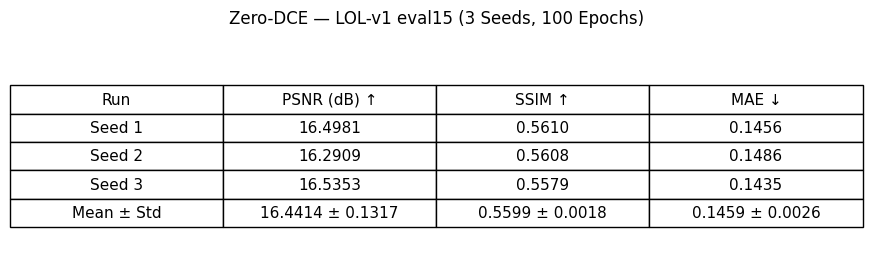

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv(OUTPUT / "seed_metrics.csv")

metrics = ["PSNR", "SSIM", "MAE"]

rows = []

for _, row in df.iterrows():
    rows.append([
        f"Seed {int(row['Seed'])}",
        *[f"{row[m]:.4f}" for m in metrics]
    ])

rows.append([
    "Mean ± Std",
    *[
        f"{df[m].mean():.4f} ± {df[m].std(ddof=1):.4f}"
        for m in metrics
    ]
])

fig, ax = plt.subplots(figsize=(11, 2.8))
ax.axis("off")

table = ax.table(
    cellText=rows,
    colLabels=["Run", "PSNR (dB) ↑", "SSIM ↑", "MAE ↓"],
    cellLoc="center",
    loc="center"
)

table.auto_set_font_size(False)
table.set_fontsize(11)
table.scale(1, 1.7)

ax.set_title(
    "Zero-DCE — LOL-v1 eval15 (3 Seeds, 100 Epochs)",
    pad=18
)

plt.savefig(
    OUTPUT / "final_results_table.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

BDD100K

In [ ]:
from google.colab import drive
from pathlib import Path
import subprocess
import os
import torch

drive.mount("/content/drive")

REPO = Path("/content/Zero-DCE/Zero-DCE_code")

if not (REPO / "model.py").exists():
    subprocess.run([
        "git", "clone",
        "https://github.com/Li-Chongyi/Zero-DCE.git",
        "/content/Zero-DCE"
    ], check=True)

os.chdir(REPO)

!pip -q install huggingface_hub pillow matplotlib numpy tqdm

CHECKPOINT = Path(
    "/content/drive/MyDrive/ZeroDCE_Results/checkpoints/seed_1/final.pth"
)

assert CHECKPOINT.exists(), f"Checkpoint not found: {CHECKPOINT}"

print("Zero-DCE ready!")
print("Checkpoint:", CHECKPOINT)
print("GPU available:", torch.cuda.is_available())

Mounted at /content/drive
Zero-DCE ready!
Checkpoint: /content/drive/MyDrive/ZeroDCE_Results/checkpoints/seed_1/final.pth
GPU available: True


In [ ]:
from huggingface_hub import list_repo_files, hf_hub_download
from pathlib import Path
import random

DATASET_ID = "dgural/bdd100k"

INPUT_DIR = Path("/content/BDD100K_candidates")
INPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Finding BDD100K images...", flush=True)

files = list_repo_files(
    repo_id=DATASET_ID,
    repo_type="dataset"
)

image_files = [
    f for f in files
    if f.startswith("data/")
    and f.lower().endswith((".jpg", ".jpeg", ".png"))
]

print("Available images:", len(image_files))

assert image_files, "No images found in BDD100K repository."

random.seed(42)
selected = random.sample(
    image_files,
    min(40, len(image_files))
)

downloaded = []

for index, filename in enumerate(selected, 1):
    try:
        source = hf_hub_download(
            repo_id=DATASET_ID,
            filename=filename,
            repo_type="dataset"
        )

        destination = INPUT_DIR / Path(filename).name

        import shutil
        shutil.copy2(source, destination)

        downloaded.append(destination)

        print(
            f"Downloaded {index}/{len(selected)}",
            flush=True
        )

    except Exception as e:
        print(f"Skipped {filename}: {e}")

print(f"\nSuccessfully downloaded {len(downloaded)} images")

assert downloaded, "No images downloaded."

Finding BDD100K images...
Available images: 10000


data/b63b1c14-f01a2f6b.jpg: reconstructing file:   0%|          |  0.00B / 77.6kB            

data/b63b1c14-f01a2f6b.jpg: downloading bytes:           |  0.00B            

Downloaded 1/40


data/b2b70230-bad4ff6e.jpg: reconstructing file:   0%|          |  0.00B / 68.6kB            

...

data/b5a4b486-dde596cb.jpg: downloading bytes:           |  0.00B            

Downloaded 39/40


data/c09f3c10-25c675f4.jpg: reconstructing file:   0%|          |  0.00B / 78.0kB            

data/c09f3c10-25c675f4.jpg: downloading bytes:           |  0.00B            

Downloaded 40/40

Successfully downloaded 40 images


In [ ]:
from PIL import Image
import numpy as np
import shutil
from pathlib import Path

SAMPLE_DIR = Path("/content/BDD100K_sample")
SAMPLE_DIR.mkdir(parents=True, exist_ok=True)

brightness_scores = []

for image_path in downloaded:
    with Image.open(image_path) as img:
        img = img.convert("RGB")
        img.thumbnail((320, 180))

        pixels = np.asarray(img, dtype=np.float32) / 255.0

        luminance = (
            0.2126 * pixels[:, :, 0] +
            0.7152 * pixels[:, :, 1] +
            0.0722 * pixels[:, :, 2]
        )

        brightness_scores.append((
            float(luminance.mean()),
            image_path
        ))

brightness_scores.sort(key=lambda x: x[0])

selected_images = []

for brightness, image_path in brightness_scores[:4]:
    destination = SAMPLE_DIR / image_path.name

    shutil.copy2(image_path, destination)

    selected_images.append(destination)

    print(
        f"{image_path.name} | Brightness: {brightness:.4f}"
    )

print("\nSelected:", len(selected_images), "BDD100K images")

c994e726-d8b6115b.jpg | Brightness: 0.0549
b5479087-2e92b8f5.jpg | Brightness: 0.0679
b5dd20c5-250725fa.jpg | Brightness: 0.0705
b83ec6be-953a634b.jpg | Brightness: 0.0846

Selected: 4 BDD100K images


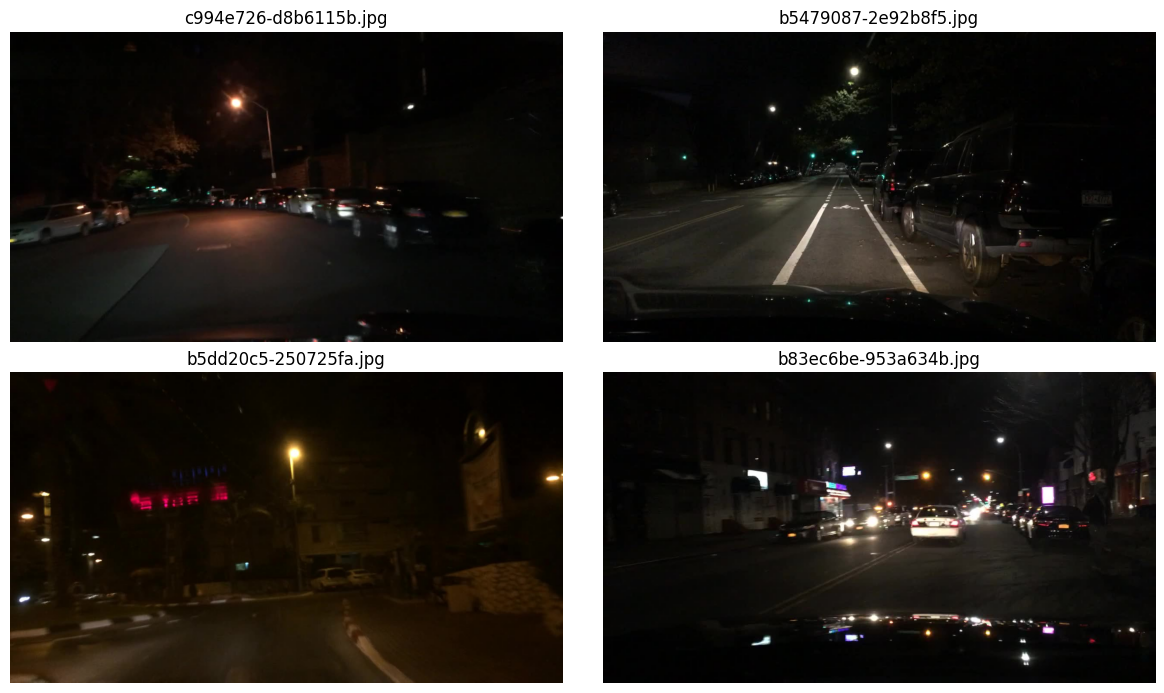

In [ ]:
import matplotlib.pyplot as plt
from PIL import Image

fig, axes = plt.subplots(2, 2, figsize=(12, 7))

for ax, image_path in zip(axes.flat, selected_images):
    ax.imshow(Image.open(image_path).convert("RGB"))
    ax.set_title(image_path.name)
    ax.axis("off")

for ax in axes.flat[len(selected_images):]:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:

import torch
import numpy as np
from PIL import Image
from pathlib import Path
from tqdm.auto import tqdm
import model

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Using device:", device)

CHECKPOINT = Path(
    "/content/drive/MyDrive/ZeroDCE_Results/checkpoints/seed_1/final.pth"
)

OUTPUT_DIR = Path(
    "/content/drive/MyDrive/ZeroDCE_Results/BDD100K"
)

ORIGINAL_DIR = OUTPUT_DIR / "original"
ENHANCED_DIR = OUTPUT_DIR / "enhanced_seed1"

ORIGINAL_DIR.mkdir(parents=True, exist_ok=True)
ENHANCED_DIR.mkdir(parents=True, exist_ok=True)

# Initialize Zero-DCE
net = model.enhance_net_nopool().to(device)

state = torch.load(
    CHECKPOINT,
    map_location=device,
    weights_only=True
)

net.load_state_dict(state)
net.eval()

print("Zero-DCE checkpoint loaded successfully!")

import shutil

with torch.inference_mode():
    for image_path in tqdm(selected_images):
        # Load original image
        image = Image.open(image_path).convert("RGB")

        # Preserve original
        shutil.copy2(
            image_path,
            ORIGINAL_DIR / image_path.name
        )

        # Convert RGB image to tensor
        image_array = (
            np.asarray(image, dtype=np.float32) / 255.0
        )

        tensor = (
            torch.from_numpy(image_array)
            .permute(2, 0, 1)
            .unsqueeze(0)
            .to(device)
        )

        # Run Zero-DCE
        _, enhanced, _ = net(tensor)

        # Convert output back to image
        enhanced = (
            enhanced.squeeze(0)
            .clamp(0, 1)
            .permute(1, 2, 0)
            .cpu()
            .numpy()
        )

        enhanced_uint8 = (
            np.clip(enhanced * 255, 0, 255)
            .round()
            .astype(np.uint8)
        )

        output_path = (
            ENHANCED_DIR / f"{image_path.stem}.png"
        )

        Image.fromarray(enhanced_uint8).save(output_path)

        print("Saved:", output_path.name)

print("\nBDD100K enhancement completed!")


Using device: cuda
Zero-DCE checkpoint loaded successfully!


  0%|          | 0/4 [00:00<?, ?it/s]

Saved: c994e726-d8b6115b.png
Saved: b5479087-2e92b8f5.png
Saved: b5dd20c5-250725fa.png
Saved: b83ec6be-953a634b.png

BDD100K enhancement completed!


In [ ]:
from PIL import Image
import matplotlib.pyplot as plt
from pathlib import Path

COMPARISON_DIR = OUTPUT_DIR / "comparisons"
COMPARISON_DIR.mkdir(parents=True, exist_ok=True)

for image_path in selected_images:
    original_path = ORIGINAL_DIR / image_path.name
    enhanced_path = ENHANCED_DIR / f"{image_path.stem}.png"

    original = Image.open(original_path).convert("RGB")
    enhanced = Image.open(enhanced_path).convert("RGB")

    fig, axes = plt.subplots(1, 2, figsize=(15, 6))

    axes[0].imshow(original)
    axes[0].set_title("Original BDD100K", fontsize=15)
    axes[0].axis("off")

    axes[1].imshow(enhanced)
    axes[1].set_title("Zero-DCE Enhanced (Seed 1)", fontsize=15)
    axes[1].axis("off")

    plt.tight_layout()

    save_path = COMPARISON_DIR / f"{image_path.stem}_comparison.png"

    plt.savefig(save_path, dpi=200, bbox_inches="tight")
    plt.show()
    plt.close(fig)

    print("Saved:", save_path.name)

Output hidden; open in https://colab.research.google.com to view.

BDD100K Filtering

In [2]:
!pip install -q gdown

In [3]:
import gdown
import zipfile
from pathlib import Path

DOWNLOAD_DIR = Path("/content/bdd100k_downloads")
DOWNLOAD_DIR.mkdir(parents=True, exist_ok=True)

url = input("Paste 100K Images ZIP URL: ").strip()

output = "/content/bdd100k_downloads/bdd100k_images.zip"

gdown.download(url, output, quiet=False, fuzzy=True)

print("Valid ZIP:", zipfile.is_zipfile(output))

url = input("Paste Detection 2020 Labels ZIP URL: ").strip()

output = "/content/bdd100k_downloads/bdd100k_labels.zip"

gdown.download(url, output, quiet=False, fuzzy=True)

print("Valid ZIP:", zipfile.is_zipfile(output))

Paste 100K Images ZIP URL: https://drive.google.com/file/d/1ZyUJH1QGVt7c7Svkfc1bEOX0hcFW1rka/view


Downloading...
From (original): https://drive.google.com/uc?id=1ZyUJH1QGVt7c7Svkfc1bEOX0hcFW1rka
From (redirected): https://drive.google.com/uc?id=1ZyUJH1QGVt7c7Svkfc1bEOX0hcFW1rka&confirm=t&uuid=f7aa37a4-1c0a-4f3b-832a-4990abb2f14a
To: /content/bdd100k_downloads/bdd100k_images.zip
100%|██████████| 5.67G/5.67G [02:00<00:00, 47.0MB/s]


Valid ZIP: True
Paste Detection 2020 Labels ZIP URL: https://drive.google.com/file/d/1GR26YSLxnctLpt-VYPa8DgeukKydK5YI/view


Downloading...
From (original): https://drive.google.com/uc?id=1GR26YSLxnctLpt-VYPa8DgeukKydK5YI
From (redirected): https://drive.google.com/uc?id=1GR26YSLxnctLpt-VYPa8DgeukKydK5YI&confirm=t&uuid=78fe1a1b-8577-41ea-a2a9-e9c9ccd08513
To: /content/bdd100k_downloads/bdd100k_labels.zip
100%|██████████| 190M/190M [00:04<00:00, 41.0MB/s]

Valid ZIP: True


In [4]:
import zipfile
from pathlib import Path

EXTRACT_DIR = Path("/content/BDD100K")
EXTRACT_DIR.mkdir(parents=True, exist_ok=True)

for filename in ["bdd100k_images.zip", "bdd100k_labels.zip"]:
    archive = DOWNLOAD_DIR / filename

    print(f"Extracting {filename}...", flush=True)

    if not zipfile.is_zipfile(archive):
        raise ValueError(f"Not a valid ZIP: {archive}")

    with zipfile.ZipFile(archive) as z:
        z.extractall(EXTRACT_DIR)

    print("Finished!")

print("All files extracted.")

Extracting bdd100k_images.zip...
Finished!
Extracting bdd100k_labels.zip...
Finished!
All files extracted.


In [5]:
from google.colab import drive
from pathlib import Path
import json
import pandas as pd
from collections import Counter

drive.mount("/content/drive")

BASE = Path("/content/drive/MyDrive/BDD100K")

ANNOTATION_DIR = BASE / "annotations"
IMAGE_DIR = BASE / "images/100k"
OUTPUT_DIR = BASE / "night_traffic_lights"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

ANNOTATION_FILES = {
    "train": ANNOTATION_DIR / "det_v2_train_release.json",
    "val": ANNOTATION_DIR / "det_v2_val_release.json"
}

for split, path in ANNOTATION_FILES.items():
    print(split, ":", "Found" if path.exists() else "MISSING")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
train : MISSING
val : MISSING


In [6]:
from pathlib import Path

root = Path("/content/BDD100K")

print("Image directories:")
for folder in root.rglob("100k"):
    if folder.is_dir() and (folder / "train").is_dir():
        print(folder)

print("\nDetection annotation files:")
for file in root.rglob("*.json"):
    if "det_" in file.name:
        print(file)

Image directories:
/content/BDD100K/100k

Detection annotation files:


In [7]:
from pathlib import Path
import json

root = Path("/content/BDD100K")

json_files = list(root.rglob("*.json"))

print("JSON files found:", len(json_files))

assert json_files, "No JSON files found!"

sample_path = json_files[0]

print("Sample file:", sample_path)

with open(sample_path) as f:
    data = json.load(f)

print(json.dumps(data, indent=2)[:5000])

JSON files found: 100000
Sample file: /content/BDD100K/100k/val/b784ff27-a05a848e.json
{
  "name": "b784ff27-a05a848e",
  "frames": [
    {
      "timestamp": 10000,
      "objects": [
        {
          "category": "traffic sign",
          "id": 0,
          "attributes": {
            "occluded": false,
            "truncated": false,
            "trafficLightColor": "none"
          },
          "box2d": {
            "x1": 404.877619,
            "y1": 438.28094,
            "x2": 417.357983,
            "y2": 460.305106
          }
        },
        {
          "category": "car",
          "id": 1,
          "attributes": {
            "occluded": true,
            "truncated": false,
            "trafficLightColor": "none"
          },
          "box2d": {
            "x1": 765.054331,
            "y1": 461.289075,
            "x2": 809.102667,
            "y2": 487.718076
          }
        },
        {
          "category": "car",
          "id": 2,
          "attributes": 

In [8]:
import json
import pandas as pd
from pathlib import Path
from collections import Counter

ROOT = Path("/content/BDD100K/100k")
OUTPUT = Path("/content/BDD100K_filtered")

OUTPUT.mkdir(parents=True, exist_ok=True)

COLORS = {"red", "yellow", "green"}

summary = []
all_boxes = []

for split in ["train", "val", "test"]:
    folder = ROOT / split

    if not folder.exists():
        print(f"Skipping missing split: {split}")
        continue

    files = sorted(folder.glob("*.json"))

    night_count = 0
    retained_count = 0
    missing_timeofday = 0
    signals = Counter()
    images_by_color = {c: set() for c in COLORS}

    split_output = OUTPUT / split
    split_output.mkdir(parents=True, exist_ok=True)

    print(f"\nProcessing {split}: {len(files)} files", flush=True)

    for path in files:
        with open(path, "r") as f:
            data = json.load(f)

        attributes = data.get("attributes") or {}

        timeofday = str(
            attributes.get("timeofday", "")
        ).strip().lower()

        if not timeofday:
            missing_timeofday += 1

        if timeofday != "night":
            continue

        night_count += 1
        filtered_frames = []

        for frame in data.get("frames", []):
            retained_objects = []

            for obj in frame.get("objects", []):
                if str(obj.get("category", "")).lower() != "traffic light":
                    continue

                color = str(
                    (obj.get("attributes") or {}).get(
                        "trafficLightColor", ""
                    )
                ).lower()

                if color not in COLORS:
                    continue

                box = obj.get("box2d")
                if not isinstance(box, dict):
                    continue

                try:
                    x1, y1, x2, y2 = (
                        float(box[k])
                        for k in ("x1", "y1", "x2", "y2")
                    )
                except (KeyError, TypeError, ValueError):
                    continue

                if x2 <= x1 or y2 <= y1:
                    continue

                retained_objects.append(obj)
                signals[color] += 1
                images_by_color[color].add(data["name"])

                all_boxes.append({
                    "split": split,
                    "image": data["name"],
                    "color": color,
                    "x1": x1,
                    "y1": y1,
                    "x2": x2,
                    "y2": y2
                })

            if retained_objects:
                filtered_frames.append({
                    **frame,
                    "objects": retained_objects
                })

        if filtered_frames:
            filtered_data = {
                **data,
                "frames": filtered_frames
            }

            with open(split_output / path.name, "w") as f:
                json.dump(filtered_data, f)

            retained_count += 1

    summary.append({
        "split": split,
        "total_images": len(files),
        "night_images": night_count,
        "retained_images": retained_count,
        "red_signals": signals["red"],
        "yellow_signals": signals["yellow"],
        "green_signals": signals["green"],
        "total_signals": sum(signals.values()),
        "images_with_red": len(images_by_color["red"]),
        "images_with_yellow": len(images_by_color["yellow"]),
        "images_with_green": len(images_by_color["green"]),
        "missing_timeofday": missing_timeofday
    })

summary_df = pd.DataFrame(summary)
boxes_df = pd.DataFrame(all_boxes)

summary_df.to_csv(OUTPUT / "split_summary.csv", index=False)
boxes_df.to_csv(OUTPUT / "traffic_light_boxes.csv", index=False)

print("\nFINAL SUMMARY")
print(summary_df.to_string(index=False))


Processing train: 70000 files

Processing val: 10000 files

Processing test: 20000 files

FINAL SUMMARY
split  total_images  night_images  retained_images  red_signals  yellow_signals  green_signals  total_signals  images_with_red  images_with_yellow  images_with_green  missing_timeofday
train         70000         28028            18202        30053            1476          43813          75342            11231                 940              14607                  0
  val         10000          3929             2535         4268             196           6089          10553             1566                 138               2017                  0
 test         20000          8036             5148         8769             436          12386          21591             3248                 271               4122                  0


In [1]:
from google.colab import drive
from pathlib import Path
import subprocess
import os
import torch

drive.mount("/content/drive")

REPO = Path("/content/Zero-DCE/Zero-DCE_code")

if not (REPO / "model.py").exists():
    subprocess.run([
        "git", "clone",
        "https://github.com/Li-Chongyi/Zero-DCE.git",
        "/content/Zero-DCE"
    ], check=True)

os.chdir(REPO)

!pip -q install pillow matplotlib numpy pandas tqdm

CHECKPOINT = Path(
    "/content/drive/MyDrive/ZeroDCE_Results/checkpoints/seed_1/final.pth"
)

assert CHECKPOINT.exists(), f"Checkpoint missing: {CHECKPOINT}"

print("Zero-DCE ready!")
print("Device:", "GPU" if torch.cuda.is_available() else "CPU")

Mounted at /content/drive
Zero-DCE ready!
Device: GPU


In [9]:
from pathlib import Path

ROOT = Path("/content/BDD100K")

image_folders = [
    p for p in ROOT.rglob("100k")
    if p.is_dir()
    and (p / "train").is_dir()
    and (p / "val").is_dir()
]

assert image_folders, (
    "BDD100K images not found. Extract the image archive first."
)

IMAGE_ROOT = image_folders[0]
LABEL_ROOT = Path("/content/BDD100K_filtered")

assert LABEL_ROOT.exists(), (
    "Filtered annotations not found. Restore the JSON files first."
)

print("Images:", IMAGE_ROOT)
print("Annotations:", LABEL_ROOT)

Images: /content/BDD100K/100k
Annotations: /content/BDD100K_filtered


In [10]:
import json
from PIL import Image
from pathlib import Path

candidates = []

for split in ["val", "train"]:
    label_folder = LABEL_ROOT / split

    if not label_folder.exists():
        continue

    for json_path in sorted(label_folder.glob("*.json")):
        with open(json_path) as f:
            data = json.load(f)

        objects = [
            obj
            for frame in data.get("frames", [])
            for obj in frame.get("objects", [])
            if obj.get("category") == "traffic light"
            and (obj.get("attributes") or {}).get("trafficLightColor")
                in {"red", "yellow", "green"}
            and isinstance(obj.get("box2d"), dict)
        ]

        if not objects:
            continue

        image_id = data.get("name", json_path.stem)
        image_path = IMAGE_ROOT / split / f"{image_id}.jpg"

        if not image_path.exists():
            continue

        # Prefer images with multiple labeled traffic lights
        candidates.append({
            "split": split,
            "path": image_path,
            "objects": objects,
            "score": len(objects)
        })

candidates.sort(key=lambda x: x["score"], reverse=True)

print("Images available with colored traffic lights:", len(candidates))

assert len(candidates) >= 5, (
    "Fewer than five matching images are available."
)

Images available with colored traffic lights: 20737


In [11]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import math

PREVIEW_COUNT = min(30, len(candidates))
preview = candidates[:PREVIEW_COUNT]

fig, axes = plt.subplots(
    math.ceil(PREVIEW_COUNT / 3), 3,
    figsize=(18, 5 * math.ceil(PREVIEW_COUNT / 3))
)

axes = axes.flatten()

for i, candidate in enumerate(preview):
    ax = axes[i]

    with Image.open(candidate["path"]) as source:
        image = source.convert("RGB")

    ax.imshow(image)

    for obj in candidate["objects"]:
        box = obj["box2d"]
        color = obj["attributes"]["trafficLightColor"]

        rect = patches.Rectangle(
            (box["x1"], box["y1"]),
            box["x2"] - box["x1"],
            box["y2"] - box["y1"],
            fill=False,
            edgecolor=color,
            linewidth=1.5
        )
        ax.add_patch(rect)

    ax.set_title(
        f"Candidate {i} | {candidate['score']} signals",
        fontsize=10
    )
    ax.axis("off")

for ax in axes[PREVIEW_COUNT:]:
    ax.axis("off")

plt.tight_layout()
plt.show()

Output hidden; open in https://colab.research.google.com to view.

In [12]:
SELECTED_INDICES = [3, 5, 6, 23, 27]

assert len(SELECTED_INDICES) == 5
assert len(set(SELECTED_INDICES)) == 5
assert all(0 <= i < len(preview) for i in SELECTED_INDICES)

selected_images = [preview[i]["path"] for i in SELECTED_INDICES]

for p in selected_images:
    print(p)

/content/BDD100K/100k/train/2acfcd8d-8fc71939.jpg
/content/BDD100K/100k/train/7d631db5-8a1cf57e.jpg
/content/BDD100K/100k/val/c24838fd-2747849c.jpg
/content/BDD100K/100k/train/1b8f494a-cd5185ec.jpg
/content/BDD100K/100k/train/4a7e3513-d24603d2.jpg


In [13]:

import torch
import numpy as np
import shutil
from pathlib import Path
from PIL import Image
from tqdm.auto import tqdm
import model

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

OUTPUT = Path(
    "/content/drive/MyDrive/ZeroDCE_Results/BDD100K_3Bulb"
)

RAW_DIR = OUTPUT / "raw"
ENHANCED_DIR = OUTPUT / "enhanced"

RAW_DIR.mkdir(parents=True, exist_ok=True)
ENHANCED_DIR.mkdir(parents=True, exist_ok=True)

# Load your trained Zero-DCE checkpoint
net = model.enhance_net_nopool().to(device)

checkpoint = torch.load(
    CHECKPOINT,
    map_location=device,
    weights_only=True
)

net.load_state_dict(checkpoint)
net.eval()

print("Model loaded successfully.")
print("Using:", device)

with torch.inference_mode():
    for i, image_path in enumerate(tqdm(selected_images), 1):

        # Save the exact original image
        raw_path = RAW_DIR / f"image_{i}_raw{image_path.suffix}"
        shutil.copy2(image_path, raw_path)

        # Load image for enhancement
        image = Image.open(image_path).convert("RGB")

        image_array = (
            np.asarray(image, dtype=np.float32) / 255.0
        )

        tensor = (
            torch.from_numpy(image_array)
            .permute(2, 0, 1)
            .unsqueeze(0)
            .to(device)
        )

        # Zero-DCE inference
        _, enhanced, _ = net(tensor)

        enhanced = (
            enhanced.squeeze(0)
            .clamp(0, 1)
            .permute(1, 2, 0)
            .cpu()
            .numpy()
        )

        enhanced_image = Image.fromarray(
            (enhanced * 255).round().astype(np.uint8)
        )

        enhanced_path = (
            ENHANCED_DIR / f"image_{i}_enhanced.png"
        )

        enhanced_image.save(enhanced_path)

        print(f"Saved image {i}:")
        print(" Raw:", raw_path)
        print(" Enhanced:", enhanced_path)

print("\nFinished enhancing all 5 images!")


Model loaded successfully.
Using: cuda


  0%|          | 0/5 [00:00<?, ?it/s]

Saved image 1:
 Raw: /content/drive/MyDrive/ZeroDCE_Results/BDD100K_3Bulb/raw/image_1_raw.jpg
 Enhanced: /content/drive/MyDrive/ZeroDCE_Results/BDD100K_3Bulb/enhanced/image_1_enhanced.png
Saved image 2:
 Raw: /content/drive/MyDrive/ZeroDCE_Results/BDD100K_3Bulb/raw/image_2_raw.jpg
 Enhanced: /content/drive/MyDrive/ZeroDCE_Results/BDD100K_3Bulb/enhanced/image_2_enhanced.png
Saved image 3:
 Raw: /content/drive/MyDrive/ZeroDCE_Results/BDD100K_3Bulb/raw/image_3_raw.jpg
 Enhanced: /content/drive/MyDrive/ZeroDCE_Results/BDD100K_3Bulb/enhanced/image_3_enhanced.png
Saved image 4:
 Raw: /content/drive/MyDrive/ZeroDCE_Results/BDD100K_3Bulb/raw/image_4_raw.jpg
 Enhanced: /content/drive/MyDrive/ZeroDCE_Results/BDD100K_3Bulb/enhanced/image_4_enhanced.png
Saved image 5:
 Raw: /content/drive/MyDrive/ZeroDCE_Results/BDD100K_3Bulb/raw/image_5_raw.jpg
 Enhanced: /content/drive/MyDrive/ZeroDCE_Results/BDD100K_3Bulb/enhanced/image_5_enhanced.png

Finished enhancing all 5 images!


In [14]:
import matplotlib.pyplot as plt
from PIL import Image

fig, axes = plt.subplots(5, 2, figsize=(15, 22))

for i in range(1, 6):
    raw_files = list(RAW_DIR.glob(f"image_{i}_raw.*"))
    assert raw_files, f"Raw image {i} missing"

    raw = Image.open(raw_files[0]).convert("RGB")
    enhanced = Image.open(
        ENHANCED_DIR / f"image_{i}_enhanced.png"
    ).convert("RGB")

    axes[i-1, 0].imshow(raw)
    axes[i-1, 0].set_title(f"Image {i}: Original BDD100K")

    axes[i-1, 1].imshow(enhanced)
    axes[i-1, 1].set_title(f"Image {i}: Zero-DCE Enhanced")

    axes[i-1, 0].axis("off")
    axes[i-1, 1].axis("off")

plt.tight_layout()
plt.show()

Output hidden; open in https://colab.research.google.com to view.